In [2]:
import mglearn
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_excel("./data/Raisin_Dataset.xlsx")

In [4]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [5]:
# 독립변수와 종속변수 분리
x = df.drop(["Area", "Class"], axis = 1)
y = df[["Class"]]

In [6]:
# 독립변수 데이터 정규화 적용
mm = MinMaxScaler()
df_minmax = mm.fit_transform(x)

In [7]:
x = pd.DataFrame(df_minmax, columns = x.columns)

In [8]:
x.head()

,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,0.280714,0.314376,0.767872,0.255504,0.831422,0.271791
1,0.234638,0.284945,0.738636,0.208864,0.667854,0.241842
2,0.280741,0.351778,0.733009,0.268084,0.565754,0.283594
3,0.078935,0.186620,0.548194,0.084089,0.701809,0.108284
4,0.164011,0.422064,0.350968,0.219472,0.906315,0.218493


In [9]:
# train/test split(7 : 3)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, stratify = y,
                                                    random_state = 23)

In [10]:
print(x_train.shape, x_test.shape)

(630, 6) (270, 6)


- KNN 모델은 거리 기반으로 분류를 하기 때문에 독립변수의 스케일을 정규화

- 7 : 3 의 비율로 학습셋과 테스트셋을 분리

In [11]:
# 기본 KNN 모델 생성 및 적용
knn = KNeighborsClassifier(n_neighbors = 5,
                           weights = "uniform",
                           metric = "minkowski")

In [12]:
knn.fit(x_train, y_train)

KNeighborsClassifier()

In [13]:
# KNN 모델 정확도
print(knn.score(x_train, y_train))
print(knn.score(x_test, y_test))

0.8857142857142857
0.8629629629629629


In [14]:
# 이웃 k 수 1 ~ 30 엘보우차트 시각화(거리 가중치 미적용)

# k 범위 지정
k_num = range(1, 31, 2)

accuracies = []

for k in k_num:
    k_num_model_1 = KNeighborsClassifier(n_neighbors = k, weights = "uniform")
    k_num_model_1.fit(x_train, y_train)
    accuracies.append(1 - k_num_model_1.score(x_test, y_test))

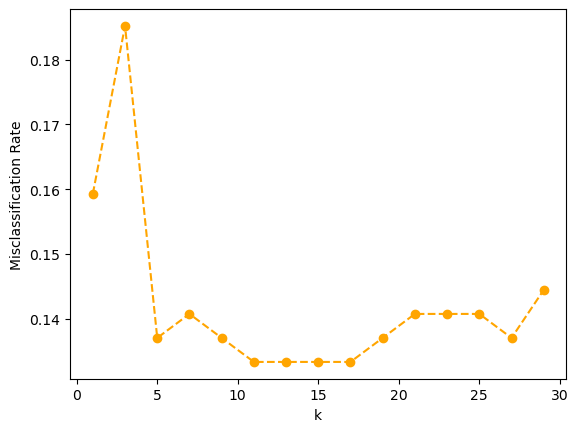

In [15]:
plt.plot(k_num, accuracies, "o--", color = "orange")
plt.xlabel("k")
plt.ylabel("Misclassification Rate")
plt.show()

In [16]:
accuracies

[0.1592592592592592,
 0.18518518518518523,
 0.13703703703703707,
 0.14074074074074072,
 0.13703703703703707,
 0.1333333333333333,
 0.1333333333333333,
 0.1333333333333333,
 0.1333333333333333,
 0.13703703703703707,
 0.14074074074074072,
 0.14074074074074072,
 0.14074074074074072,
 0.13703703703703707,
 0.1444444444444445]

- 거리 가중치를 적용하지 않은 모델에서 k 이웃 수를 1에서 30까지 늘려가며 KNN 모델의 오분류율을 시각화

- 이웃 수가 11개일 때 오분류율이 가장 낮아져서 k는 11일 때 가장 적합함

In [17]:
# 이웃 k 수 1 ~ 30까지 엘보우차트 시각화(거리 가중치 적용)

# k 범위 지정
k_num = range(1, 31, 2)

accuracies = []

for k in k_num:
    k_num_model_2 = KNeighborsClassifier(n_neighbors = k, weights = "distance")
    k_num_model_2.fit(x_train, y_train)
    accuracies.append(1 - k_num_model_2.score(x_test, y_test))

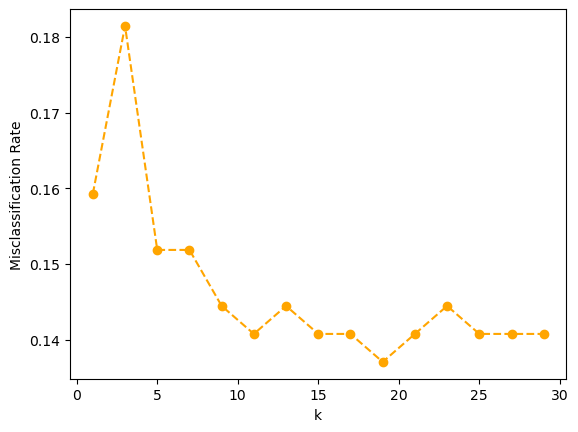

In [18]:
plt.plot(k_num, accuracies, "o--", color = "orange")
plt.xlabel("k")
plt.ylabel("Misclassification Rate")
plt.show()

In [19]:
accuracies

[0.1592592592592592,
 0.18148148148148147,
 0.1518518518518519,
 0.1518518518518519,
 0.1444444444444445,
 0.14074074074074072,
 0.1444444444444445,
 0.14074074074074072,
 0.14074074074074072,
 0.13703703703703707,
 0.14074074074074072,
 0.1444444444444445,
 0.14074074074074072,
 0.14074074074074072,
 0.14074074074074072]

In [20]:
# 이웃 k 수 1 ~ 200까지 엘보우차트 시각화(거리 가중치 적용)

# k 범위 지정
k_num = range(1, 200, 2)

accuracies = []

for k in k_num:
    k_num_model_2 = KNeighborsClassifier(n_neighbors = k, weights = "distance")
    k_num_model_2.fit(x_train, y_train)
    accuracies.append(1 - k_num_model_2.score(x_test, y_test))

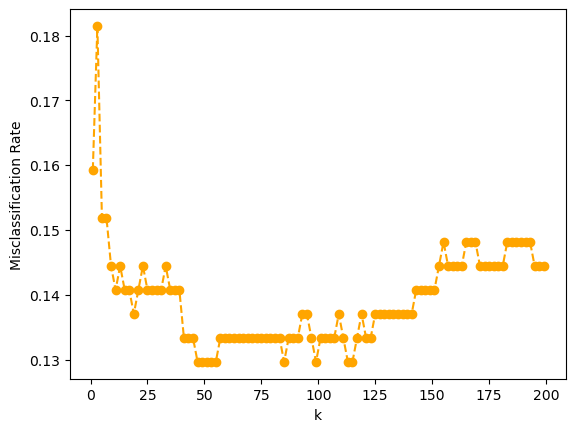

In [21]:
plt.plot(k_num, accuracies, "o--", color = "orange")
plt.xlabel("k")
plt.ylabel("Misclassification Rate")
plt.show()

In [22]:
# 시각화를 위한 차원 축소(6차원 -> 2차원)

# 주성분 개수 설정(2개)
pca = PCA(n_components = 2)
df_pca = pca.fit_transform(x_test)

In [23]:
df_pca = pd.DataFrame(df_pca, columns = ["C1", "C2"])

In [24]:
df_pca.head()

,C1,C2
0,0.066943,0.019918
1,-0.090469,0.038150
2,0.580079,-0.309505
3,0.180463,0.256873
4,-0.039189,-0.059272


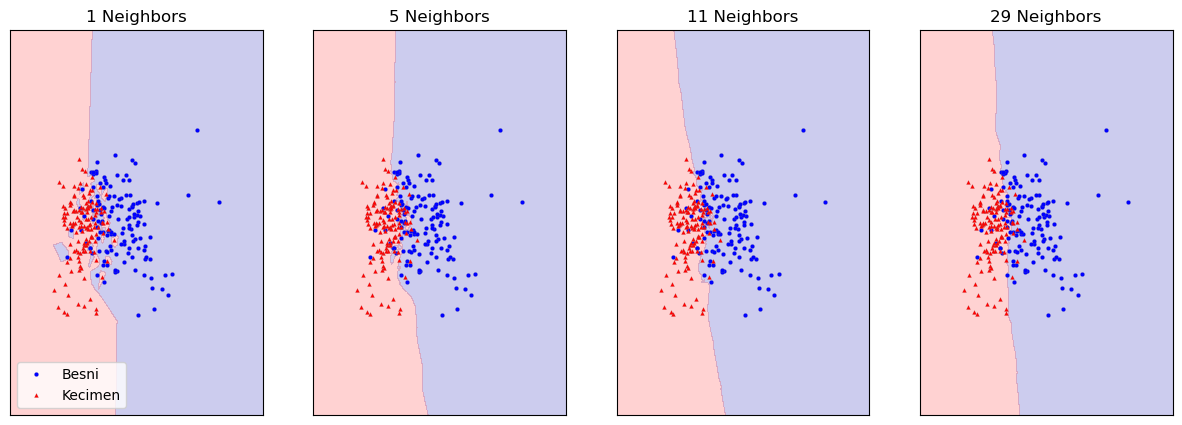

In [31]:
# 결정 경계선(decision boundary) 시각화 확인

df_vsl_x = df_pca.to_numpy()
df_vsl_y = y_test["Class"].to_numpy()

# 그래프 설정
cmap_bold = ListedColormap(["#FF0000", "#00FF00"])
fig, axes = plt.subplots(1, 4, figsize = (15, 5))

# 이웃 수 1, 5, 11, 29 에 따른 결정 경계 시각화
for n_neighbors, ax in zip([1, 5, 11, 29], axes):
    k_num_model_eg = KNeighborsClassifier(n_neighbors = n_neighbors).fit(df_vsl_x, df_vsl_y)

    mglearn.plots.plot_2d_separator(k_num_model_eg, df_vsl_x, fill = True, eps = 0.5, ax = ax,
                                    alpha = 0.2)
    mglearn.discrete_scatter(df_vsl_x[:, 0], df_vsl_x[:, 1], df_vsl_y,
                             markeredgewidth = 0.1,
                             c = ["b", "r"], s = 3, ax = ax)
    ax.set_title(f"{n_neighbors} Neighbors")

axes[0].legend(loc = 3)
plt.show()

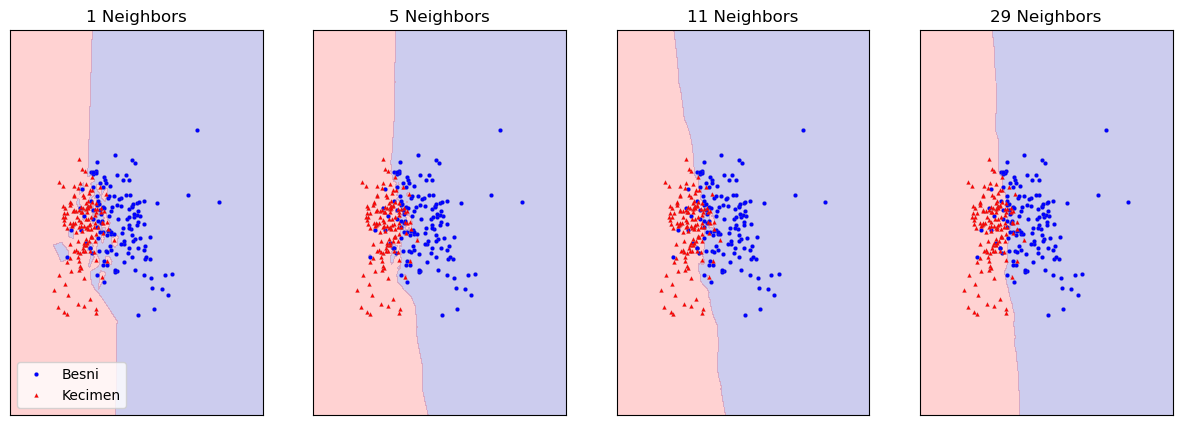

In [33]:
fig, axes = plt.subplots(1, 4, figsize = (15, 5))

# 이웃 수 1, 5, 11, 29 에 따른 결정 경계 시각화
for n_neighbors, ax in zip([1, 5, 11, 29], axes):
    k_num_model_eg = KNeighborsClassifier(n_neighbors = n_neighbors,
                                          weights = "distance").fit(df_vsl_x, df_vsl_y)

    mglearn.plots.plot_2d_separator(k_num_model_eg, df_vsl_x, fill = True, eps = 0.5, ax = ax,
                                    alpha = 0.2)
    mglearn.discrete_scatter(df_vsl_x[:, 0], df_vsl_x[:, 1], df_vsl_y,
                             markeredgewidth = 0.1,
                             c = ["b", "r"], s = 3, ax = ax)
    ax.set_title(f"{n_neighbors} Neighbors")

axes[0].legend(loc = 3)
plt.show()